# Compara mayo con mayo

**Jornada 4 · Bloque 4.2 · Series temporales a ojo**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

cafe = lab.cargar_cafeteria(DATOS)
series = lab.cargar_series(DATOS, cafe)
print(f"Datos listos: {len(series['bici'])} meses de viajes de BiciCiudad y "
      f"{len(series['cafe'])} meses de ventas de Café Molienda")

Datos listos: 35 meses de viajes de BiciCiudad y 24 meses de ventas de Café Molienda


## La pregunta

En noviembre, los viajes de BiciCiudad caen un 21 % y el cuadro de mando se pone en rojo. Alguien
convoca una reunión de crisis. Mientras tanto, fuera hace frío. Como todos los noviembres.

## El experimento

Elige la serie (los viajes de BiciCiudad o las ventas de las doce cafeterías de Café Molienda), el mes y
con qué lo comparas. Cada línea es un año. El semáforo sigue la regla del cuadro de mando: verde si sube,
rojo si baja. El estado inicial es el del cuadro de mando del curso: noviembre de 2025 frente a octubre.

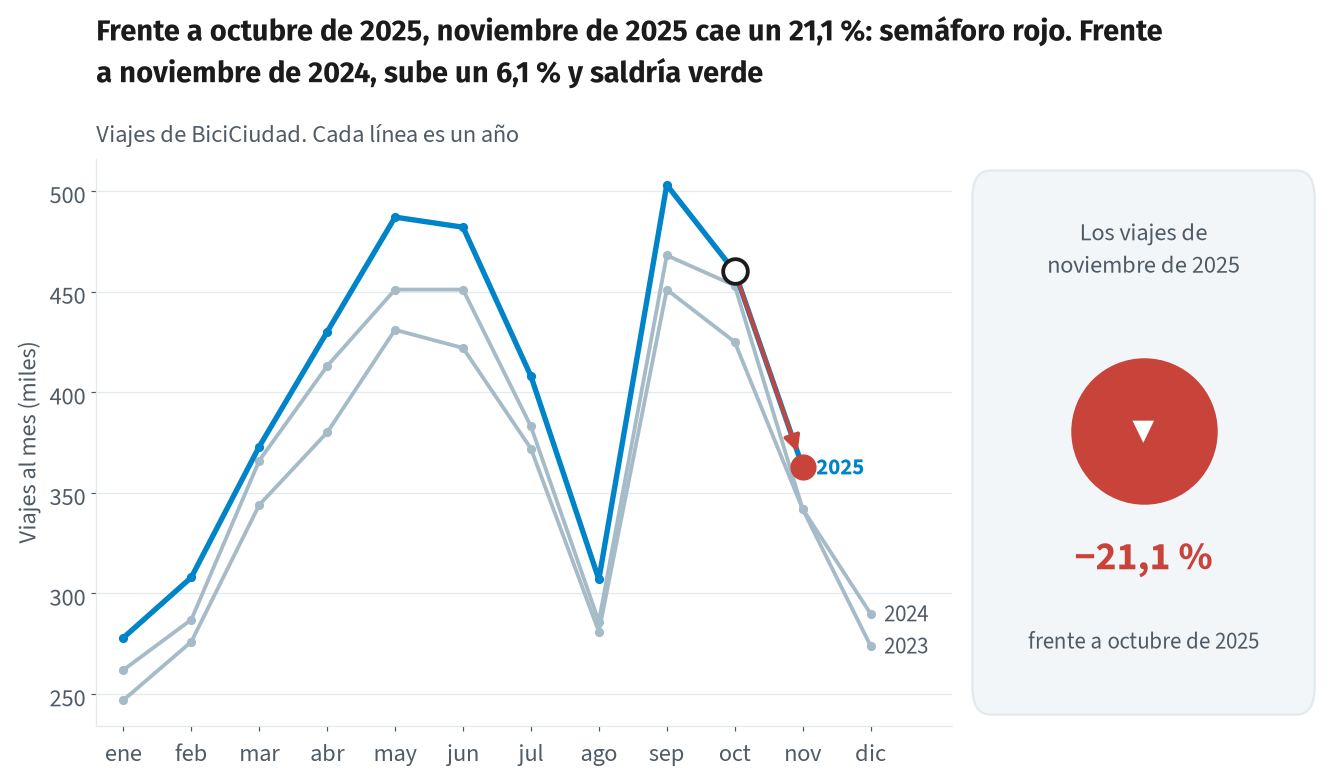

In [2]:
# El experimento: el mismo mes, comparado de dos formas.
serie = widgets.ToggleButtons(options=[("Viajes de BiciCiudad", "bici"), ("Ventas de Café Molienda", "cafe")],
                              value="bici", description="Serie:", style=BOTONES)
mes = widgets.Dropdown(options=lab.meses_disponibles(series, "bici"), value="2025-11",
                       description="Mes:", style=ESTILO)
comparacion = widgets.ToggleButtons(
    options=[("Con el mes anterior", "anterior"), ("Con el mismo mes del año anterior", "interanual")],
    value="anterior", description="Comparar:", style=BOTONES)


def cambiar_serie(cambio):
    # Cada serie tiene sus meses: se conserva el elegido si existe en la nueva.
    opciones = lab.meses_disponibles(series, cambio["new"])
    valores = [v for _, v in opciones]
    actual = mes.value
    mes.options = opciones
    mes.value = actual if actual in valores else valores[-1]


serie.observe(cambiar_serie, names="value")


def dibujar(serie, mes, comparacion):
    if mes not in [v for _, v in lab.meses_disponibles(series, serie)]:
        return  # el desplegable se está actualizando
    lab.mostrar(lab.dibujar_estacionalidad(series, serie, mes, comparacion))


grafico = widgets.interactive_output(dibujar, {"serie": serie, "mes": mes, "comparacion": comparacion})
display(widgets.VBox([serie, mes, comparacion, grafico]))

## Qué observar

1. Noviembre de 2025 frente a octubre y frente a noviembre de 2024: ¿qué semáforo dirías que es el bueno?
2. Recorre los meses de 2025 comparando con el mes anterior. ¿Cuántos rojos salen? ¿Y comparando con el
   mismo mes del año anterior?
3. En la cafetería, agosto frente a julio: ¿crisis o vacaciones?
4. ¿Qué meses engañan más cuando se comparan con el mes anterior?

## Mensaje clave

> **Compara mayo con mayo.**

Y si la serie tiene estacionalidad, el semáforo también debería tenerla en cuenta.

## Para curiosos

En el avanzado se separan tendencia, estacionalidad y ruido con una descomposición de la serie y se usan
gráficos de control para decidir qué mes malo merece reunión y cuál es simplemente un mes.